<a href="https://colab.research.google.com/github/Douaa-Nozomi/cytokine-analysis/blob/main/tp2_open_science.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng = np.random.default_rng(seed=2025)
plt.rcParams['figure.figsize'] = (7, 4)


In [2]:
conc = np.array([0, 2, 4, 6, 8, 10]) # μg/mL
absorbance = 0.0512 * conc + 0.004 + rng.normal(0, 0.008, conc.size)
absorbance = absorbance.round(3)
pd.DataFrame({"concentration (μg/mL)": conc, "absorbance": absorbance})

,concentration (μg/mL),absorbance
0,0,-0.014
1,2,0.107
2,4,0.204
3,6,0.302
4,8,0.394
5,10,0.522


In [3]:

# 1) Droite de régression
pente, ordonnee = np.polyfit(conc, absorbance, 1)
# 2) Coefficient de détermination R²
A_calc = pente * conc + ordonnee # absorbance calculée par la droite
ss_res = np.sum((absorbance - A_calc) ** 2) # écarts entre mesure et droite
ss_tot = np.sum((absorbance- np.mean(absorbance)) ** 2) # écarts entre mesure et moyenne
R2 = 1 - ss_res / ss_tot
# 3) Affichage
print(f"pente = {pente:.4f} | ordonnée = {ordonnee:.4f} | R² = {R2:.4f}")

pente = 0.0520 | ordonnée = -0.0074 | R² = 0.9975


Dans la cuvette : 6.11 μg/mL | Solution mère : 30.5 μg/mL


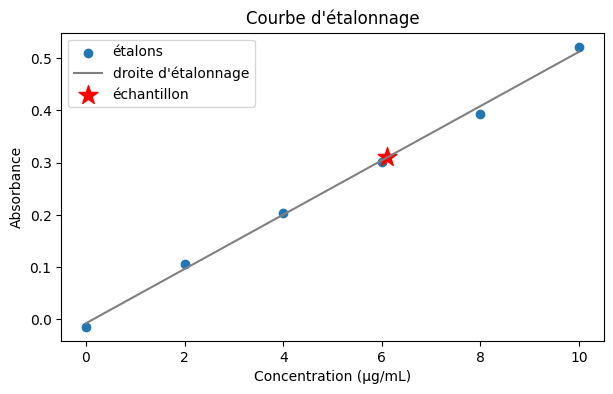

In [4]:
A_inconnu = 0.310
dilution = 5
C_cuvette = (A_inconnu - ordonnee) / pente    # concentration dans la cuvette (μg/mL)
C_mere = C_cuvette * dilution # concentration de la solution mère (μg/mL)
print(f"Dans la cuvette : {C_cuvette:.2f} μg/mL | Solution mère : {C_mere:.1f} μg/mL")
# Graphique
plt.scatter(conc, absorbance, label="étalons")
plt.plot(conc, A_calc, color="gray", label="droite d'étalonnage")
# marker: l'étoile s'écrit "*"
plt.scatter(C_cuvette, A_inconnu, marker="*", s=200, color="red", label="échantillon")
plt.title("Courbe d'étalonnage")
plt.xlabel("Concentration (μg/mL)")
plt.ylabel("Absorbance")
plt.legend()
plt.show()

Votre repence:Q1=a ,Q2=b ,Q3=a

In [26]:
from scipy.optimize import curve_fit
def michaelis(S, Vmax, Km):
 return Vmax * S / (Km + S)
S = np.array([0.5, 1, 2, 5, 10, 20, 50, 100]) # mM
# mM, concentration de l'inhibiteur
I = 10
v_sans = (michaelis(S, 120, 8) * np.random.normal(1, 0.04, S.size)).round(1)
v_avec = (michaelis(S, 120, 8 * (1 + I / 5)) * np.random.normal(1, 0.04, S.size)).round(1)
pd.DataFrame({"S (mM)": S, "v sans inhibiteur": v_sans, "v avec inhibiteur": v_avec})

,S (mM),v sans inhibiteur,v avec inhibiteur
0,0.5,7.0,2.5
1,1.0,13.3,4.8
2,2.0,25.0,8.5
3,5.0,47.1,20.8
4,10.0,68.2,35.8
5,20.0,91.4,51.6
6,50.0,103.6,77.7
7,100.0,112.5,102.9


In [27]:
# Sans inhibiteur
param_sans, _ = curve_fit(michaelis, S, v_sans, p0=[100, 5])
Vmax_sans, Km_sans = param_sans

# Avec inhibiteur
param_avec, _ = curve_fit(michaelis, S, v_avec, p0=[100, 5])
Vmax_avec, Km_avec = param_avec

# Affichage
pd.DataFrame({"Vmax": [Vmax_sans, Vmax_avec], "Km (mM)": [Km_sans, Km_avec]},
             index=["sans inhibiteur", "avec inhibiteur"]).round(1)

,Vmax,Km (mM)
sans inhibiteur,121.4,7.6
avec inhibiteur,129.3,29.0


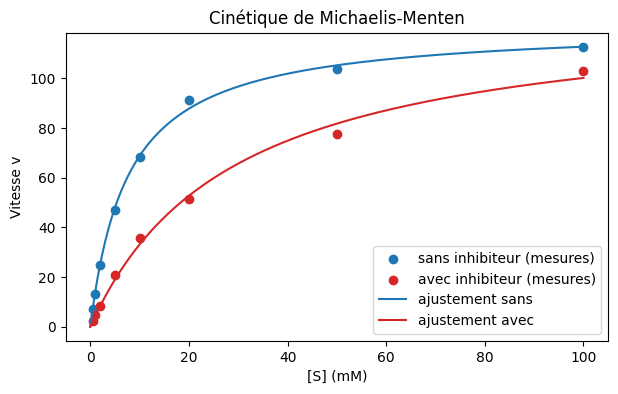

In [28]:
S_fin = np.linspace(0, 100, 300)
plt.scatter(S, v_sans, color="tab:blue", label="sans inhibiteur (mesures)")
plt.scatter(S, v_avec, color="tab:red", label="avec inhibiteur (mesures)")
plt.plot(S_fin, michaelis(S_fin, Vmax_sans, Km_sans), color="tab:blue", label="ajustement sans")
plt.plot(S_fin, michaelis(S_fin, Vmax_avec, Km_avec), color="tab:red", label="ajustement avec")
plt.title("Cinétique de Michaelis-Menten")
plt.xlabel("[S] (mM)")
plt.ylabel("Vitesse v")
plt.legend()
plt.show()

In [29]:
Ki = I / (Km_avec / Km_sans - 1)
print(f"Ki = {Ki:.1f} mM\n")

# Votre réponse:
print("Q1 = b  (Vmax ne change presque pas)")
print("Q2 = a  (Km augmente)")
print("Q3 = a  (Inhibition compétitive)")

Ki = 3.6 mM

Q1 = b  (Vmax ne change presque pas)
Q2 = a  (Km augmente)
Q3 = a  (Inhibition compétitive)


In [13]:
def hill(logC, Emin, Emax, logEC50, n):
  return Emin + (Emax - Emin) / (1 + 10 ** ((logEC50 - logC) * n))
logC = np.arange(-9, -3.5, 0.5) # log10 de la concentration (M)
effet_A = (hill(logC, 2, 98, -7.0, 1.0) + rng.normal(0, 3, logC.size)).round(1)
effet_B = (hill(logC, 2, 98, -6.3, 1.0) + rng.normal(0, 3, logC.size)).round(1)
pd.DataFrame({"logC": logC, "effet A (%)": effet_A, "effet B (%)": effet_B})

,logC,effet A (%),effet B (%)
0,-9.0,0.9,4.5
1,-8.5,13.8,4.5
2,-8.0,8.7,3.2
3,-7.5,28.8,7.2
4,-7.0,45.0,18.4
5,-6.5,73.7,39.8
6,-6.0,85.0,66.4
7,-5.5,95.6,87.2
8,-5.0,102.5,93.0
9,-4.5,95.0,98.1


In [30]:
pA, _ = curve_fit(hill, logC, effet_A, p0=[0, 100, -7, 1])
EC50_A = 10 ** pA[2] * 1e9

pB, _ = curve_fit(hill, logC, effet_B, p0=[0, 100, -7, 1])
EC50_B = 10 ** pB[2] * 1e9

tableau = pd.DataFrame({"Emax": [pA[1], pB[1]], "pEC50": [-pA[2], -pB[2]], "EC50 (nM)": [EC50_A, EC50_B], "pente de Hill": [pA[3], pB[3]]}, index=["Composé A", "Composé B"]).round(2)
print(tableau, "\n")

# Votre réponse Partie 3
print("Q1 = a | Q2 = a | Q3 = a")

             Emax  pEC50  EC50 (nM)  pente de Hill
Composé A  100.03   6.92     120.99           0.89
Composé B   98.59   6.29     508.14           1.04 

Q1 = a | Q2 = a | Q3 = a


In [15]:
dose = 500 # mg
t = np.array([0.25, 0.5, 1, 2, 4, 6, 8, 12, 24]) # h
conc_pl = (12.5 * np.exp(-0.173 * t) * rng.normal(1, 0.05, t.size)).round(2) # mg/L
pk = pd.DataFrame({"temps (h)": t, "concentration (mg/L)": conc_pl})
pk

,temps (h),concentration (mg/L)
0,0.25,11.30
1,0.50,10.94
2,1.00,10.81
3,2.00,9.06
4,4.00,6.60
5,6.00,3.93
6,8.00,3.23
7,12.00,1.38
8,24.00,0.20


In [32]:
ln_conc = np.log(conc_pl)
pente_pk, ordonnee_pk = np.polyfit(t, ln_conc, 1)
k = -pente_pk
C0 = np.exp(ordonnee_pk)
t_demi = np.log(2) / k
Vd = dose / C0
print(f"k = {k:.3f} 1/h | C0 = {C0:.1f} mg/L | t1/2 = {t_demi:.1f} h | Vd = {Vd:.0f} L\n")
AUC = np.sum((conc_pl[:-1] + conc_pl[1:]) / 2 * np.diff(t))
print(f"AUC(0-24h) = {AUC:.1f} mg·h/L")

k = 0.173 1/h | C0 = 12.2 mg/L | t1/2 = 4.0 h | Vd = 41 L

AUC(0-24h) = 70.2 mg·h/L
